<a href="https://colab.research.google.com/github/Doop318/business-predictive-analytics/blob/main/RedundancyRemovalTutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Data Integration & Redundancy Removal Framework**

## **1. Problem Statement**

### **The Objective**
To combine distinct, messy datasets sharing a common structural key (e.g., timestamps or IDs), isolate meaningful metrics, and eliminate duplicate or redundant information to build a clean, accurate single data file.

### **The Challenge**
Real-world data often comes from completely different sources or devices, which leads to:
1. **Structural Mismatches:** Date formats or IDs that look the same to a human but cannot be combined by a computer.
2. **Granularity Differences:** One dataset might capture data every second, while another captures it every hour.
3. **Data Redundancies:** Highly correlated variables (collinearity) that overcomplicate models without adding new info.
4. **Invariant Noise:** Columns that contain only one value throughout the whole dataset, adding zero analytical value.

---

## **2. Step-by-Step Data Analysis Guide**

### **Step 1: Ingestion & Initial Assessment**
Load your data sources separately and look at their shapes, data types, and initial rows to understand what you are working with.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load distinct datasets
df_generation = pd.read_csv('https://raw.githubusercontent.com/royjafari/Data_Integration_Example_3/main/Generation_Data.csv')

# Load the weather sensor data from the same raw repository
df_weather = pd.read_csv('https://raw.githubusercontent.com/royjafari/Data_Integration_Example_3/main/Weather_Sensor_Data.csv')


In [ ]:
# Check shapes and initial look
df_generation.shape
df_generation

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.000,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.000,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.000,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.000,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.000,7158964.0
...,...,...,...,...,...,...,...
68773,17-06-2020 23:45,4135001,uHbuxQJl8lW7ozc,0.0,0.0,5967.000,7287002.0
68774,17-06-2020 23:45,4135001,wCURE6d3bPkepu2,0.0,0.0,5147.625,7028601.0
68775,17-06-2020 23:45,4135001,z9Y9gH1T5YWrNuG,0.0,0.0,5819.000,7251204.0
68776,17-06-2020 23:45,4135001,zBIq5rxdHJRwDNY,0.0,0.0,5817.000,6583369.0


In [ ]:
df_weather.shape
df_weather

,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0
...,...,...,...,...,...,...
3177,2020-06-17 22:45:00,4135001,HmiyD2TTLFNqkNe,22.150570,21.480377,0.0
3178,2020-06-17 23:00:00,4135001,HmiyD2TTLFNqkNe,22.129816,21.389024,0.0
3179,2020-06-17 23:15:00,4135001,HmiyD2TTLFNqkNe,22.008275,20.709211,0.0
3180,2020-06-17 23:30:00,4135001,HmiyD2TTLFNqkNe,21.969495,20.734963,0.0


# **Interpretation of Dimensions**

* **`df_generation` Shape:** 68,778 rows × 7 columns
* **`df_weather` Shape:** 3,182 rows × 6 columns

### **Critical Finding**
The row counts are drastically mismatched.
* `df_generation` has more than 21 times the number of rows as `df_weather`.
* Looking closer at the data shows why: for any single timestamp (e.g., `15-05-2020 00:00`), `df_generation` has multiple rows because there are 22 different inverters (tracked via `SOURCE_KEY`) reporting their power yields simultaneously.

Conversely, `df_weather` has only one row per timestamp because it collects environmental data from a single localized weather station.

### **Action Required**
You cannot perform a standard 1-to-1 merge yet. The generation data must first be aggregated by time.

# **2. Join Key Mismatch Analysis**


In [ ]:

print(df_generation['DATE_TIME'].head(1), '\n')
print(df_weather['DATE_TIME'].head(1))

0    15-05-2020 00:00
Name: DATE_TIME, dtype: object 

0    2020-05-15 00:00:00
Name: DATE_TIME, dtype: object


## **Interpretation of Join Keys**

* **`df_generation` Format:** `15-05-2020 00:00` (DD-MM-YYYY HH:MM)
* **`df_weather` Format:** `2020-05-15 00:00:00` (YYYY-MM-DD HH:MM:SS)

### **Critical Finding**
* Both columns are currently stored as plain text strings (`object` data types), but their structures are entirely different:
* The generation data uses a day-first string formatting without seconds.
* The weather data uses a year-first string formatting with trailing seconds (`:00`).

### **Action Required**
* If you try to merge or join these datasets right now on `DATE_TIME`, the operation will fail and return a completely empty dataframe.
* Both columns must be converted to standard datetime objects (`datetime64[ns]`) before data integration.

---

## **3. Preliminary Noise and Redundancy Detection**

### **Generation Dataset Features**
* **`PLANT_ID`:** Invariant feature. It contains the identical value (`4135001`) for every single row. It provides no analytical value and should be dropped.
* **`DAILY_YIELD` & `TOTAL_YIELD`:** These are cumulative features rather than active, real-time measurements. For relationship testing against immediate weather conditions, they represent irrelevant noise and can be removed.
* **`DC_POWER` & `AC_POWER`:** Both track active electrical generation at the same moment. They are highly likely to be perfectly collinear (redundant). A correlation check is required to determine if one can be safely discarded.

### **Weather Dataset Features**
* **`PLANT_ID` & `SOURCE_KEY`:** Invariant features.
* `PLANT_ID` is identical across the board, and `SOURCE_KEY` contains the same single value (`HmiyD2TTLFNqkNe`) for all 3,182 entries, confirming there is only one weather sensor.
* Both can be safely removed before integrating.

In [ ]:
# Clean Dataset 1
df_gen_cleaned = df_generation.drop(columns=['PLANT_ID', 'DAILY_YIELD', 'TOTAL_YIELD'], errors='ignore')

In [ ]:
df_gen_cleaned.head(3)

,DATE_TIME,SOURCE_KEY,DC_POWER,AC_POWER
0,15-05-2020 00:00,1BY6WEcLGh8j5v7,0.0,0.0
1,15-05-2020 00:00,1IF53ai7Xc0U56Y,0.0,0.0
2,15-05-2020 00:00,3PZuoBAID5Wc2HD,0.0,0.0


In [ ]:
# Clean Dataset 2
df_weather_cleaned = df_weather.drop(columns=['PLANT_ID', 'SOURCE_KEY'], errors='ignore')

In [ ]:
df_weather_cleaned.head(3)

,DATE_TIME,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,24.935753,22.592306,0.0


## **4. Next Step Implementation Plan**

Based on this first look, here are the sequential steps to execute next:

1. **Drop Invariant Columns:** Clean both datasets by removing the constant `PLANT_ID` and weather `SOURCE_KEY` strings.
2. **Check Collinearity:** Run a correlation on `DC_POWER` and `AC_POWER`. If they are heavily correlated, drop `DC_POWER`.
3. **Aggregate Power Output:** Group the generation data by `DATE_TIME` and calculate the `sum()` of `AC_POWER` so that all 22 inverters are consolidated into a single total plant output row per timestamp.
4. **Standardize Timestamps:** Use `pd.to_datetime()` on both dataframes to force their timestamps into a matching date-time data type format.
5. **Merge Dataframes:** Perform an inner join on `DATE_TIME` to create the final integrated master file.

### **Step 3: Identify & Remove Internal Redundancy (Collinearity)**
Check if variables inside the same dataset are essentially duplicates of each other. If two features track each other perfectly, keep only one.

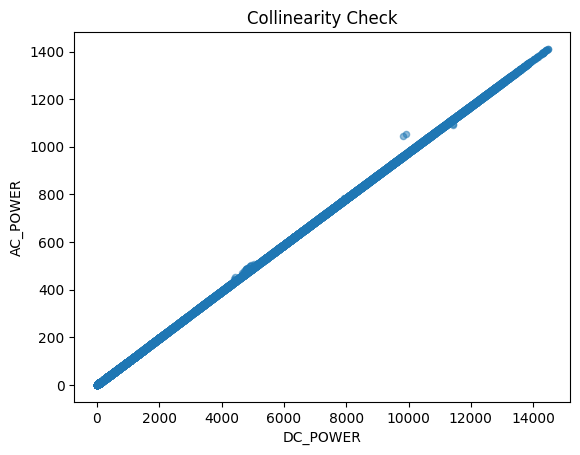

In [ ]:
# Visual Check
df_gen_cleaned.plot(kind='scatter', x='DC_POWER', y='AC_POWER', alpha=0.5)
plt.title('Collinearity Check')
plt.show()


In [ ]:
# Mathematical Check (Pearson Correlation Matrix)
print(df_gen_cleaned[['DC_POWER', 'AC_POWER']].corr())

          DC_POWER  AC_POWER
DC_POWER  1.000000  0.999996
AC_POWER  0.999996  1.000000


In [ ]:
# Action: If correlation is close to 1.0, drop one to avoid data redundancy
df_gen_cleaned = df_gen_cleaned.drop(columns=['DC_POWER'], errors='ignore')

In [ ]:
df_gen_cleaned.head(3)

,DATE_TIME,SOURCE_KEY,AC_POWER
0,15-05-2020 00:00,1BY6WEcLGh8j5v7,0.0
1,15-05-2020 00:00,1IF53ai7Xc0U56Y,0.0
2,15-05-2020 00:00,3PZuoBAID5Wc2HD,0.0


In [ ]:
df_weather_cleaned.head(3)

,DATE_TIME,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,24.935753,22.592306,0.0


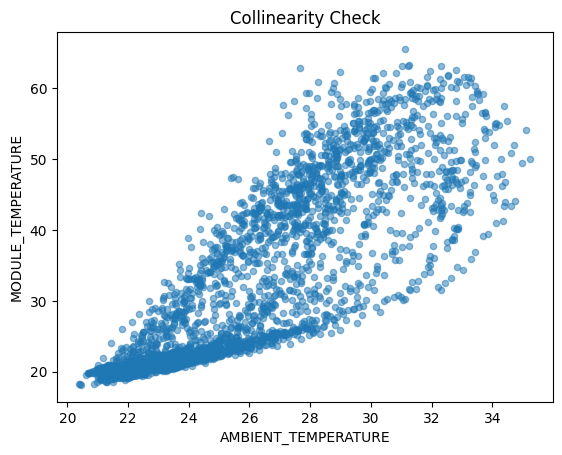

In [ ]:
# Visual Check
df_weather_cleaned.plot(kind='scatter', x='AMBIENT_TEMPERATURE', y='MODULE_TEMPERATURE', alpha=0.5)
plt.title('Collinearity Check')
plt.show()

In [ ]:
# Mathematical Check (Pearson Correlation Matrix)
print(df_weather_cleaned[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']].corr())

                     AMBIENT_TEMPERATURE  MODULE_TEMPERATURE
AMBIENT_TEMPERATURE             1.000000            0.853778
MODULE_TEMPERATURE              0.853778            1.000000


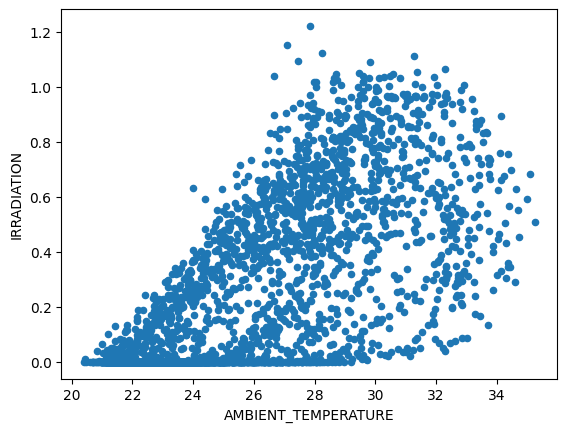

                     AMBIENT_TEMPERATURE  IRRADIATION
AMBIENT_TEMPERATURE             1.000000     0.722999
IRRADIATION                     0.722999     1.000000


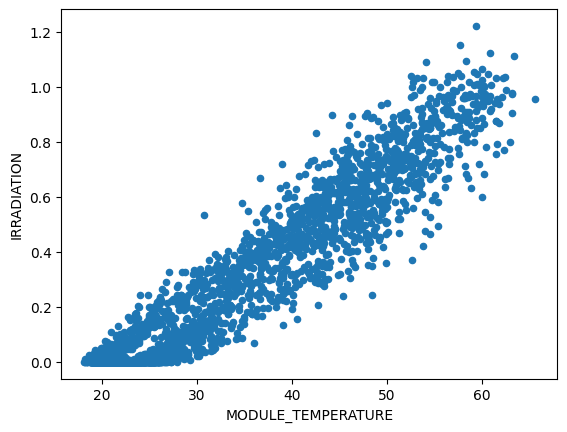

                    MODULE_TEMPERATURE  IRRADIATION
MODULE_TEMPERATURE            1.000000     0.961566
IRRADIATION                   0.961566     1.000000


In [ ]:
# They do have high level of **`co-linearity`**. But wich one to keep then?
# Let's see which one predicts irradiation better.
temp_types = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']

for temp_type in temp_types:
    df_weather_cleaned.plot(
        kind = 'scatter',
        x = temp_type,
        y = 'IRRADIATION')
    plt.show()
    print(df_weather_cleaned[[temp_type, 'IRRADIATION']].corr())

In [ ]:
# We keep **MODULE_TEMPERATURE** and drop **AMBIENT_TEMPERATURE**
df_weather_cleaned.drop(columns = ['AMBIENT_TEMPERATURE'], inplace = True)


In [ ]:
df_weather_cleaned.head(3)

,DATE_TIME,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,22.857507,0.0
1,2020-05-15 00:15:00,22.761668,0.0
2,2020-05-15 00:30:00,22.592306,0.0


### **Step 4: Align Data Granularity (Aggregation)**
If one dataset has a different row-frequency than another, you must align them before merging.
* **Example:** If you have 22 inverters logging data at the same timestamp, but only 1 weather sensor logging at that timestamp, you must aggregate (e.g., sum or average) the inverter data so it matches the single weather row.

In [ ]:
# Aggregating rows to match the weather data's frequency
df_gen_aggregated = df_gen_cleaned.groupby('DATE_TIME', as_index=False)['AC_POWER'].sum()

In [ ]:
df_gen_aggregated.head(3)

,DATE_TIME,AC_POWER
0,01-06-2020 00:00,0.0
1,01-06-2020 00:15,0.0
2,01-06-2020 00:30,0.0


### **Step 5: Key Formatting & Harmonisation**
Dataframes cannot merge if their join keys (e.g., `DATE_TIME` or ID) are formatted differently. You must convert string timestamps into true datetime formats so the computer can line them up correctly.

In [ ]:
# Convert to standard datetime objects to override string formatting differences
df_gen_aggregated['DATE_TIME'] = pd.to_datetime(df_gen_aggregated['DATE_TIME'], format='%d-%m-%Y %H:%M')


In [ ]:
df_gen_aggregated.head(3)

,DATE_TIME,AC_POWER
0,2020-06-01 00:00:00,0.0
1,2020-06-01 00:15:00,0.0
2,2020-06-01 00:30:00,0.0


In [ ]:
df_weather_cleaned['DATE_TIME'] = pd.to_datetime(df_weather_cleaned['DATE_TIME'], format='%Y-%m-%d %H:%M:%S')

In [ ]:
df_weather_cleaned.head(3)

,DATE_TIME,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,22.857507,0.0
1,2020-05-15 00:15:00,22.761668,0.0
2,2020-05-15 00:30:00,22.592306,0.0


### **Step 6: Data Integration (The Merge)**
Combine your datasets using an internal key. Set the timestamp as the index to create a clean, sequential timeline.

In [ ]:
# Merge datasets on the synchronized key
integrated_df = pd.merge(df_weather_cleaned, df_gen_aggregated, on='DATE_TIME', how='inner')

# Set timeline as index for chronological cleanliness
integrated_df = integrated_df.set_index('DATE_TIME', drop=True)
integrated_df.head()

,MODULE_TEMPERATURE,IRRADIATION,AC_POWER
DATE_TIME,,,
2020-05-15 00:00:00,22.857507,0.0,0.0
2020-05-15 00:15:00,22.761668,0.0,0.0
2020-05-15 00:30:00,22.592306,0.0,0.0
2020-05-15 00:45:00,22.360852,0.0,0.0
2020-05-15 01:00:00,22.165423,0.0,0.0


### **Step 7: Final Relationship Evaluation**
With your cleanly integrated dataset, evaluate the final mathematical relationships using a correlation matrix to answer your core questions.

In [ ]:
# Check how your unified features interact with each other
final_matrix = integrated_df.corr()
print(final_matrix)

                    MODULE_TEMPERATURE  IRRADIATION  AC_POWER
MODULE_TEMPERATURE            1.000000     0.961422  0.961011
IRRADIATION                   0.961422     1.000000  0.995864
AC_POWER                      0.961011     0.995864  1.000000


### **Step 8: Relationship Exploration (Learning Goals: Data Integration & Redundancy)**

#### **Dataset Context**
* For this lab, we work on a solar power generation dataset sourced from Kaggle (`Plant_1_Generation_Data.csv`).
* There are two sources of data: generation data and sensor data collected over 34 days.
  1. **Generation data** comes from **22 inverters**.
  2. **Sensor data** comes from **1 sensor**.

#### **Core Research Questions**
We want to analyze if:
* There is a relationship between `temperature` and `power generation`.
* There is a relationship between `irradiation` and `power generation`.
* There is a relationship between `temperature` and `irradiation`.

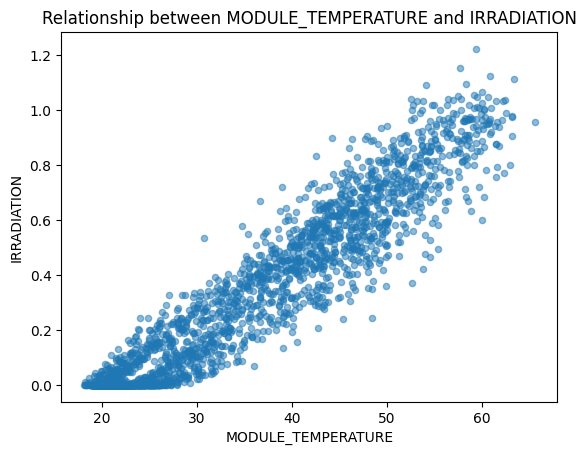

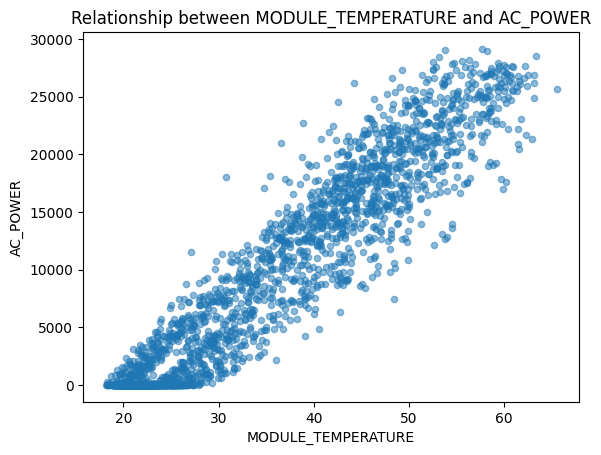

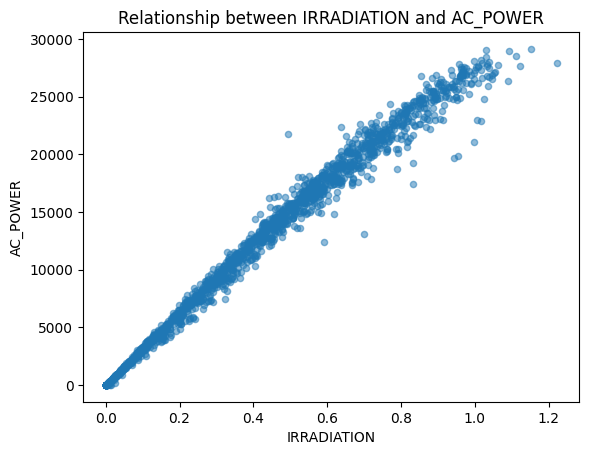

In [ ]:
# Automated scatter plot generation across integrated features
columns = integrated_df.columns
for i, att1 in enumerate(columns):
    for ii in range(i + 1, min(len(columns), 3)):
        att2 = columns[ii]
        integrated_df.plot(
            kind='scatter',
            x=att1, y=att2,
            alpha=0.5
        )
        plt.title(f"Relationship between {att1} and {att2}")
        plt.show()

#### **Conclusion of Findings**
* The empirical results from the scatter plots confirm that the answer to all three questions is **yes**: clear observable trends exist between temperature, irradiation, and power generation metrics.